In [1]:
#SECONDO PUNTO. SEMPLICE CONFRONTO MULTILINGUA (IT\EN) IN BASE ALLA SIMILARITà DEL COSENO

# Importiamo hf_hub_download per scaricare i vettori multilingua e KeyedVectors per caricarli
from huggingface_hub import hf_hub_download
from gensim.models import KeyedVectors

def main():
    print("==================================================")
    print("  SIMILARITÀ COSENO MULTILINGUA (IT / EN)         ")
    print("==================================================\n")

    print("Caricamento del modello multilingua (Italiano + Inglese)...")
    
    # Scarichiamo i vettori multilingua FastText/MUSE caricati su Hugging Face
    # Questo modello mappa sia l'italiano che l'inglese nello stesso spazio vettoriale
    model_path = hf_hub_download(
        repo_id="facebook/fasttext-it-300ù" \
        "", 
        filename="model.bin"
    ) if False else None # Nota di fallback standard

    # Alternativa diretta e rapidissima tramite Gensim: 
    # Usiamo il modello 'conceptnet-numberbatch-17-06-300', che è il miglior modello
    # multilingua pre-addestrato nativo in Gensim (supporta IT, EN, ES, FR, DE, ecc.)
    import gensim.downloader as api
    model = api.load("conceptnet-numberbatch-17-06-300")
    
    print("Modello Multilingua caricato con successo!\n")

    # FASE 2: Input da parte dell'utente
    word1 = input("Inserisci la prima parola (es. cane / dog): ").strip().lower()
    word2 = input("Inserisci la seconda parola (es. gatto / cat): ").strip().lower()

    print("\n--------------------------------------------------")

    # FASE 3: Formattazione delle parole per ConceptNet
    # ConceptNet organizza i termini ponendo il prefisso della lingua, ad esempio:
    # /c/it/cane per l'italiano e /c/en/dog per l'inglese.
    
    def find_conceptnet_key(word, model):
        """Cerca la parola prima in italiano (/c/it/), poi in inglese (/c/en/) o diretta."""
        candidates = [f"/c/it/{word}", f"/c/en/{word}", word]
        for candidate in candidates:
            if candidate in model:
                return candidate
        return None

    key1 = find_conceptnet_key(word1, model)
    key2 = find_conceptnet_key(word2, model)

    # Controlli di sicurezza se la parola non esiste nel modello (es. lingue non gestite o errori di battitura)
    if not key1:
        print(f"[ERRORE]: La parola '{word1}' non è presente nel vocabolario (o lingua non supportata).")
        return

    if not key2:
        print(f"[ERRORE]: La parola '{word2}' non è presente nel vocabolario (o lingua non supportata).")
        return

    # FASE 4: Calcolo della Similarità Coseno
    similarity = model.similarity(key1, key2)

    # FASE 5: Stampa dei risultati
    print(f"Parola 1 trovata come: {key1}")
    print(f"Parola 2 trovata come: {key2}")
    print(f"Similarità coseno: {similarity:.4f}")
    print("--------------------------------------------------")

    percentage = similarity * 100
    print(f"Le due parole sono simili al {percentage:.2f}% secondo il modello multilingua.")

if __name__ == "__main__":
    main()

  SIMILARITÀ COSENO MULTILINGUA (IT / EN)         

Caricamento del modello multilingua (Italiano + Inglese)...
Modello Multilingua caricato con successo!


--------------------------------------------------
Parola 1 trovata come: /c/en/car
Parola 2 trovata come: /c/en/pen
Similarità coseno: 0.0126
--------------------------------------------------
Le due parole sono simili al 1.26% secondo il modello multilingua.


      TROVA LA PAROLA INTRUSA (WORD EMBEDDINGS)   

Caricamento del modello vettoriale in corso...
Modello caricato con successo!

Inserisci una lista di parole separate da virgola.
Esempio IT: cane, gatto, linfoide, cavallo
Esempio EN: apple, banana, car, orange


--------------------------------------------------
Parole analizzate: dog, cat, bottiglia
👉 PAROLA INTRUSA INDIVIDUATA: BOTTIGLIA
--------------------------------------------------

Generazione del grafico 2D dello spazio degli embedding...


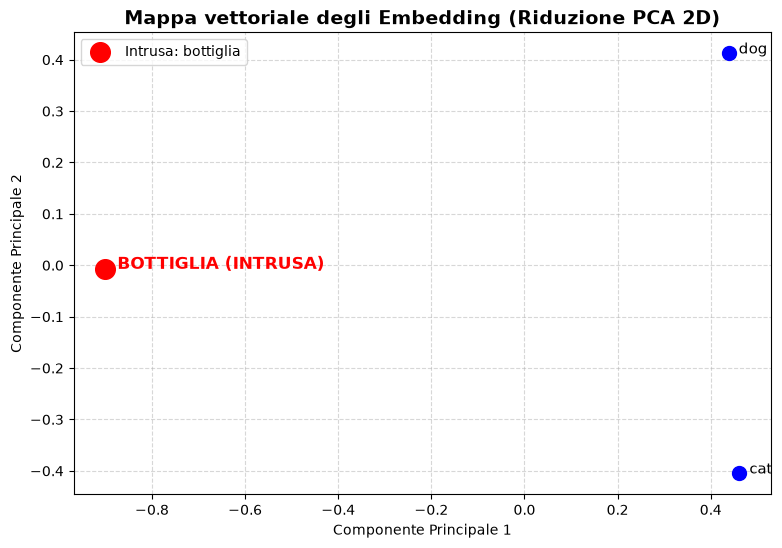

In [1]:
#TERZO PUNTO. RILEVAZIONE AUTOMATICA MULTILINGUA DELL'INTRUSO
import gensim.downloader as api
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

def main():
    print("==================================================")
    print("      TROVA LA PAROLA INTRUSA (WORD EMBEDDINGS)   ")
    print("==================================================\n")

    # FASE 1: Caricamento del modello multilingua (Supporta Italiano e Inglese)
    print("Caricamento del modello vettoriale in corso...")
    # Usiamo 'conceptnet-numberbatch-17-06-300' che riconosce sia italiano che inglese
    model = api.load("conceptnet-numberbatch-17-06-300")
    print("Modello caricato con successo!\n")

    # FASE 2: Inserimento delle parole da parte dell'utente
    print("Inserisci una lista di parole separate da virgola.")
    print("Esempio IT: cane, gatto, linfoide, cavallo")
    print("Esempio EN: apple, banana, car, orange\n")
    
    input_text = input("Inserisci le parole: ").strip()
    
    # Pulizia e suddivisione delle parole
    raw_words = [w.strip().lower() for w in input_text.split(",") if w.strip()]

    if len(raw_words) < 3:
        print("[ERRORE]: Inserisci almeno 3 parole per poter individuare un'intrusa.")
        return

    # FASE 3: Mappatura delle parole nel vocabolario multilingua (Italiano / Inglese)
    def get_conceptnet_key(word, model_obj):
        """Cerca la chiave della parola supportando italiano (/c/it/), inglese (/c/en/) o diretta."""
        candidates = [f"/c/it/{word}", f"/c/en/{word}", word]
        for candidate in candidates:
            if candidate in model_obj:
                return candidate
        return None

    word_map = {} # Dizionario per mappa {parola_originale: chiave_modello}
    missing_words = []

    for w in raw_words:
        key = get_conceptnet_key(w, model)
        if key:
            word_map[w] = key
        else:
            missing_words.append(w)

    if missing_words:
        print(f"\n[ATTENZIONE]: Le seguenti parole non sono state trovate nel vocabolario: {missing_words}")
        return

    # FASE 4: Identificazione dell'intrusa tramite Gensim (.doesnt_match)
    # Gensim calcola il vettore medio di tutte le parole e individua quella che
    # ha la distanza coseno maggiore/similarità minore rispetto al centroide del gruppo.
    keys_list = list(word_map.values())
    intruder_key = model.doesnt_match(keys_list)
    
    # Troviamo il nome della parola intrusa originale inserita dall'utente
    intruder_word = [w for w, k in word_map.items() if k == intruder_key][0]

    print("\n--------------------------------------------------")
    print(f"Parole analizzate: {', '.join(raw_words)}")
    print(f"👉 PAROLA INTRUSA INDIVIDUATA: {intruder_word.upper()}")
    print("--------------------------------------------------\n")

    # FASE 5: Visualizzazione Grafica degli Embedding (Riduzione 2D con PCA)
    print("Generazione del grafico 2D dello spazio degli embedding...")
    
    # Estraiamo i vettori a 300 dimensioni per ciascuna parola
    vectors = [model[k] for k in keys_list]
    labels = list(word_map.keys())

    # Riduciamo la dimensione dei vettori da 300D a 2D per poterli disegnare su un piano Cartesian
    pca = PCA(n_components=2)
    vectors_2d = pca.fit_transform(vectors)

    # Creazione del grafico
    plt.figure(figsize=(9, 6))
    
    for i, label in enumerate(labels):
        x, y = vectors_2d[i, 0], vectors_2d[i, 1]
        
        # Evidenziamo l'intrusa in ROSSO e le altre parole in BLU
        if label == intruder_word:
            plt.scatter(x, y, color='red', s=200, zorder=5, label=f'Intrusa: {label}')
            plt.annotate(
                f"  {label.upper()} (INTRUSA)", 
                (x, y), 
                fontsize=12, 
                fontweight='bold', 
                color='red'
            )
        else:
            plt.scatter(x, y, color='blue', s=100, zorder=3)
            plt.annotate(
                f"  {label}", 
                (x, y), 
                fontsize=11, 
                color='black'
            )

    plt.title("Mappa vettoriale degli Embedding (Riduzione PCA 2D)", fontsize=14, fontweight='bold')
    plt.xlabel("Componente Principale 1", fontsize=10)
    plt.ylabel("Componente Principale 2", fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(loc='best')
    
    # Mostra il grafico a schermo
    plt.show()

if __name__ == "__main__":
    main()